# 9 · Fault interpretation for 2-D restoration: auto-detect, import, trace by hand

**Why.** In Notebook 8 the three fault-restoration methods (planar flexural cantilever, listric fault + inclined simple shear, rigid domino blocks) were run with fault positions picked by eye and a 45° dip that was **assumed**. Part of the remaining misfit probably comes from that fault geometry. This notebook adds three ways to get fault planes, all returning `flex2d.Fault` objects that go straight into `flex2d.restore(sec, faults, method=...)`:

1. **Auto-detection** (`pybasinsubs.faults`): from horizon offsets (throw discontinuities linked into fault sticks), and from a section image (Canny edges + Hough lines, scikit-image).
2. **Import**: CSV fault sticks, simple Petrel (Charisma), Kingdom and OpendTect fault-stick ASCII layouts, and GeoJSON lines.
3. **Interactive manual tracing** of several faults: the `pybasinsubs-app` browser app (fault editor page), able to add, edit and delete faults, save/load JSON or CSV, and run the restoration with the chosen method.

Then the Notebook 8 comparison is re-run with the auto-detected geometry for all three methods.

**Methods available** (`flex2d.restore(..., method=)`): `'cantilever'` (Kusznir et al. 1991, 1995), `'listric'` (inclined antithetic simple shear only, α default 65°; **vertical shear is not offered**), `'domino'`. Optional dependency: scikit-image (image detection). The fault-editor app needs only the package's own dependencies (FastAPI, Uvicorn).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
IMG = os.path.join(ROOT, "image"); os.makedirs(IMG, exist_ok=True)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
def save(fig, name):
    fig.savefig(os.path.join(IMG, name), bbox_inches="tight"); print("saved image/" + name)
from pybasinsubs import data_path, flex2d, faults as F, faultfit as FF
dv = pd.read_csv(data_path("north_sea", "roberts1998_fig4a_vg1_digitized.csv"))
xg = np.arange(1000.0, 81001.0, 250.0); Iv = lambda c: np.interp(xg, dv.x_km * 1e3, dv[c])
vtops = np.array([Iv(f"top{L}_m") for L in range(1, 11)]); vbase = Iv("base_m")
VUNITS = ["Pliocene-Recent", "Miocene", "Eocene-Oligocene", "Palaeocene", "Upper Cretaceous", "Lower Cretaceous",
          "Kimmeridgian-Ryazanian (Draupne)", "Callovian-Oxfordian (Heather)", "Bajocian-Bathonian (Brent)", "Triassic-Lower Jurassic"]
VAGES = [0, 5.3, 23.0, 56.0, 66.0, 100.5, 140.0, 157.3, 166.1, 170.3]
VLITH = [{"shale": 1}] * 4 + [{"chalk": 1}, {"shale": 1}, {"shale": 1}, {"shale": 1}, {"sandstone": 1}, {"shaly_sandstone": 1}]
from pybasinsubs.material_colors import section_material_colors
VCOL = section_material_colors(VUNITS)  # shared display colors only
# Frozen legacy RGB input: changing display colors must not change Canny/Hough geometry.
DETECTION_COLORS = ["#f08068", "#60a0c0", "#f8f000", "#b840a8", "#00a050", "#e81820", "#8070c0", "#908888", "#60a0c0", "#f8f000"]
vsec = flex2d.section_from_horizons(xg, vtops, vbase, VUNITS, VAGES, VAGES[1:] + [252.0], VLITH, vtops[0])
vfaults = [flex2d.fault_at(xg, vtops, x0 * 1e3, down=1, win=1500.0, dip=45.0, label=l,
                           source="picked by eye on the digitized section; dip assumed")
           for x0, l in zip([6.75, 19.0, 29.25, 44.25, 65.75], ["margin", "Heather|Pelican", "Pelican|Hutton", "Hutton|Brent", "Brent|Gullfaks"])]
def draw_section(ax, tops=vtops, base=vbase, x=xg):
    for k in range(len(tops)):
        ax.fill_between(x / 1e3, tops[k], tops[k + 1] if k + 1 < len(tops) else base, color=VCOL[k], lw=0, alpha=.85)
    ax.set_ylim(np.nanmax(base) + 200, -200); ax.set_xlabel("distance (km)"); ax.set_ylabel("depth (m)")

## 2-D analysis order — fixed-trace VG1 prototype

Inspect the present-day input and the compaction model before explicitly reconstructing growth. The following cells use the same helpers and default traces as the app. No tip-extension or trace-position assist is applied.

### 1 · Present-day interpreted section

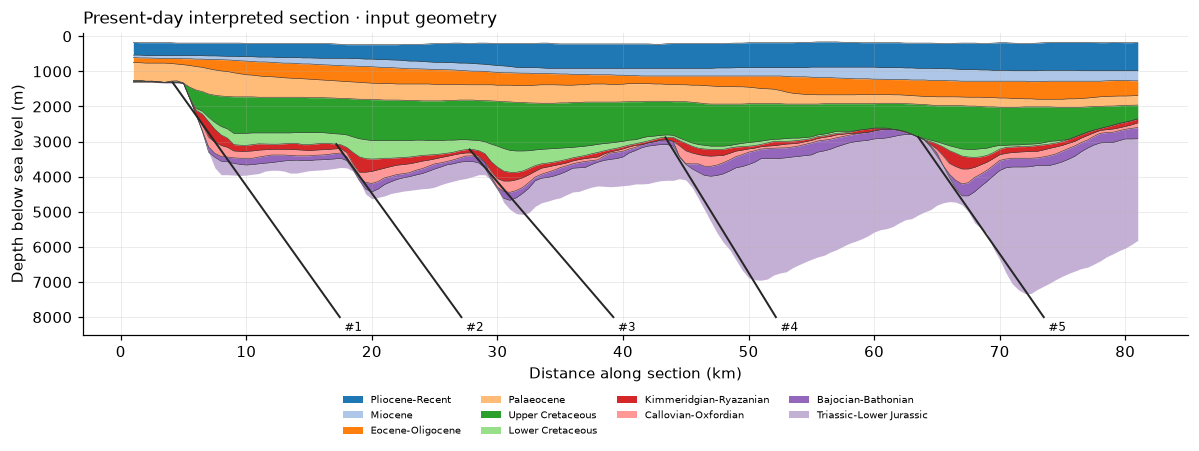

In [2]:
%matplotlib inline
from pybasinsubs.input_plots import stratigraphic_column, compaction_relations, interpreted_section
from IPython.display import display
import matplotlib.pyplot as plt
plt.ioff()
from pybasinsubs import app_core as analysis_core
analysis_section, analysis_faults = analysis_core.load_section()
fig = interpreted_section(analysis_section, analysis_faults)
display(fig)
plt.close(fig)


### 2 · Porosity–depth relations

These central lithology curves are the actual decompaction inputs. VG1 contains no measured porosity points; the helper does not manufacture scatter or refit the curves.

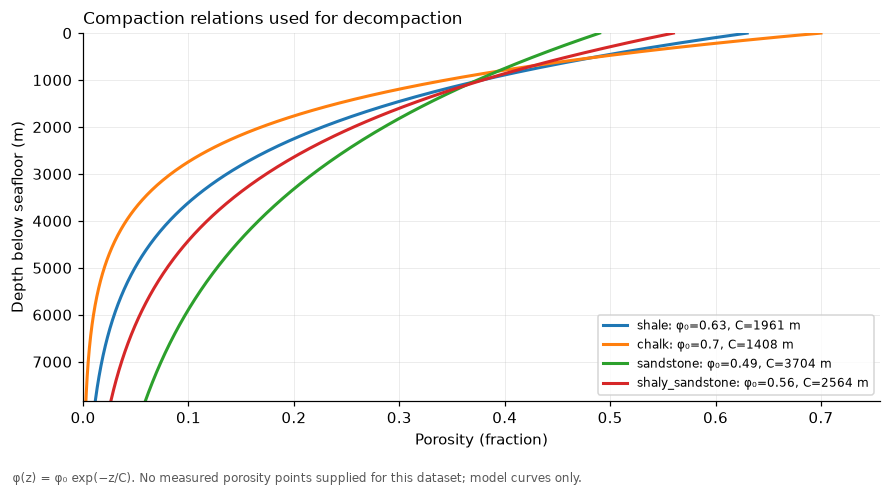

In [3]:
fig = compaction_relations(analysis_section)
display(fig)
plt.close(fig)


### 3 · Explicit growth reconstruction — one timestep per figure

This is nonnegative, regularized vertical-shear **apparent throw**, not resolved down-dip slip, geological heave or curved-fault balancing. Zero is assumed. The oldest interval retains 170.3-Ma geometry, not an inferred 252-Ma restoration. Rates show spatial / fitting-sensitivity ranges, not confidence intervals. Remaining traces are slipped and top-clipped; #1–#5 labels default on. All timestep figures share one shape and all-timestep axis limits.

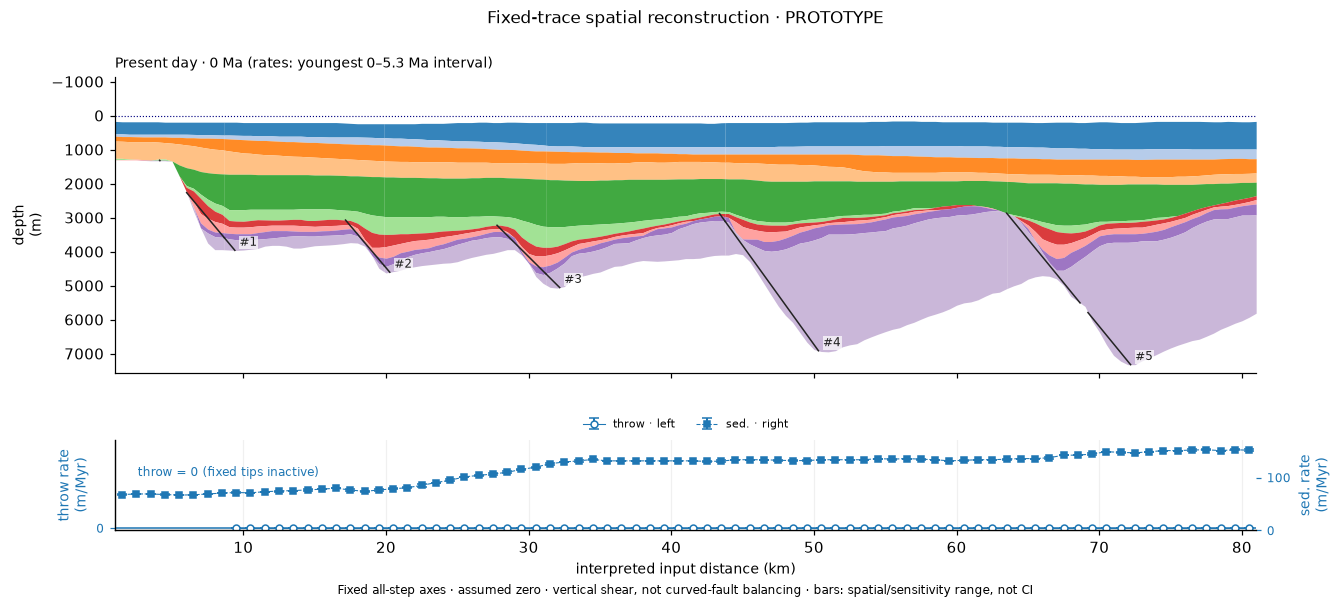

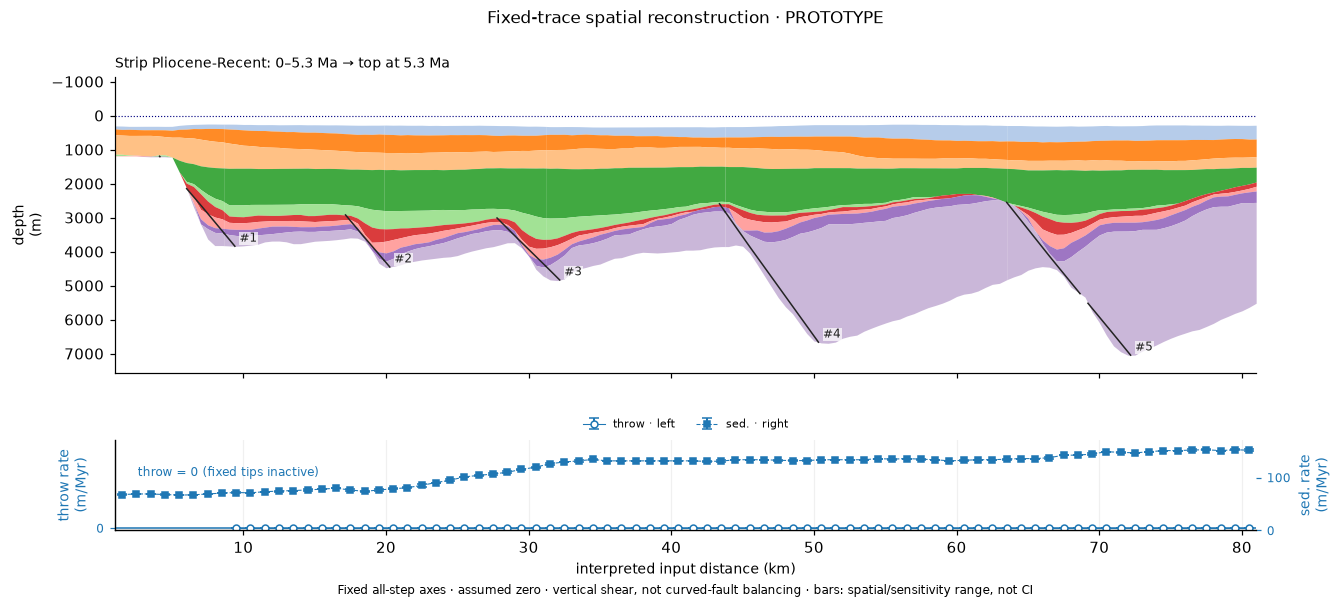

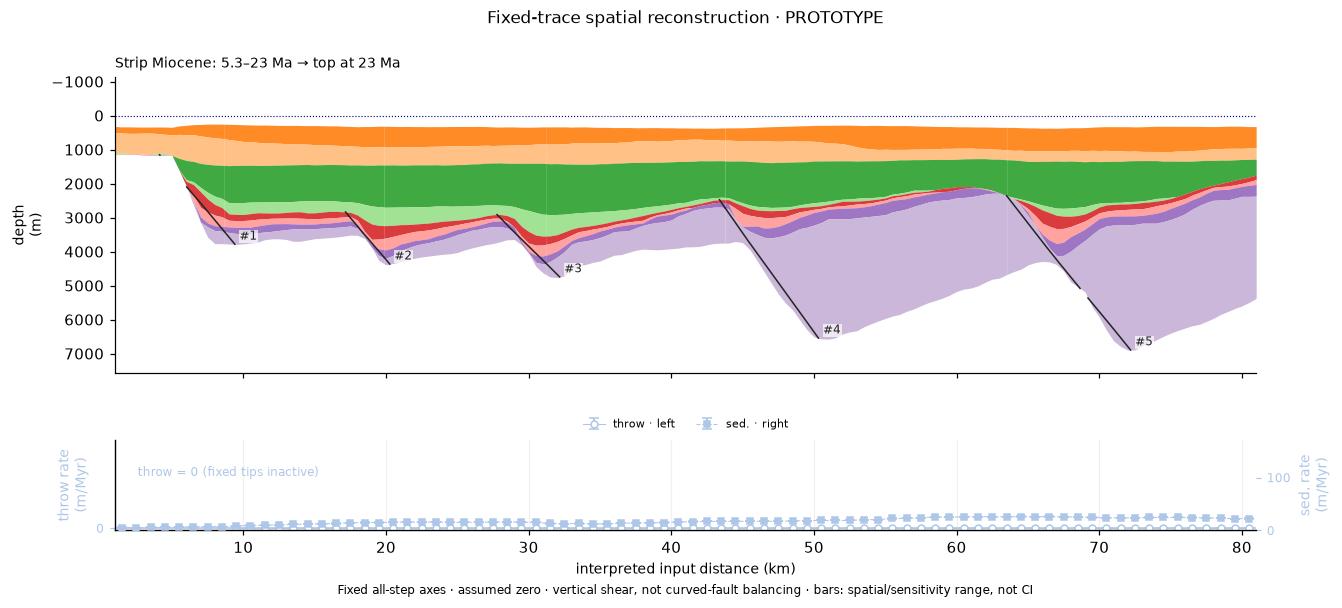

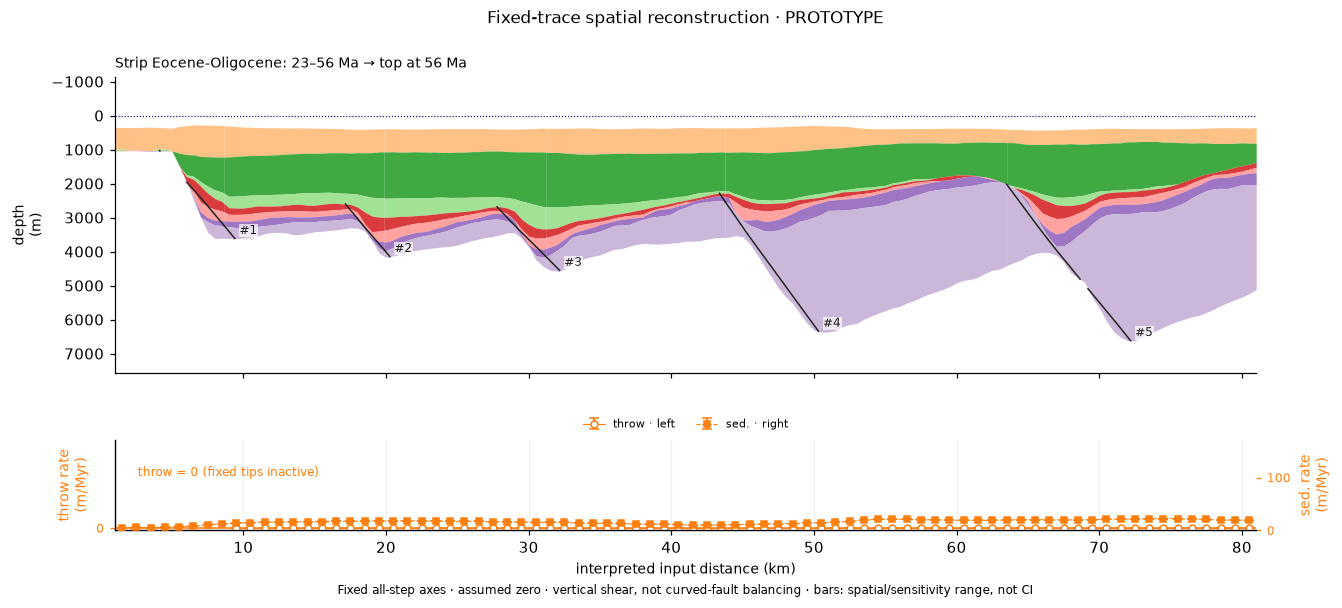

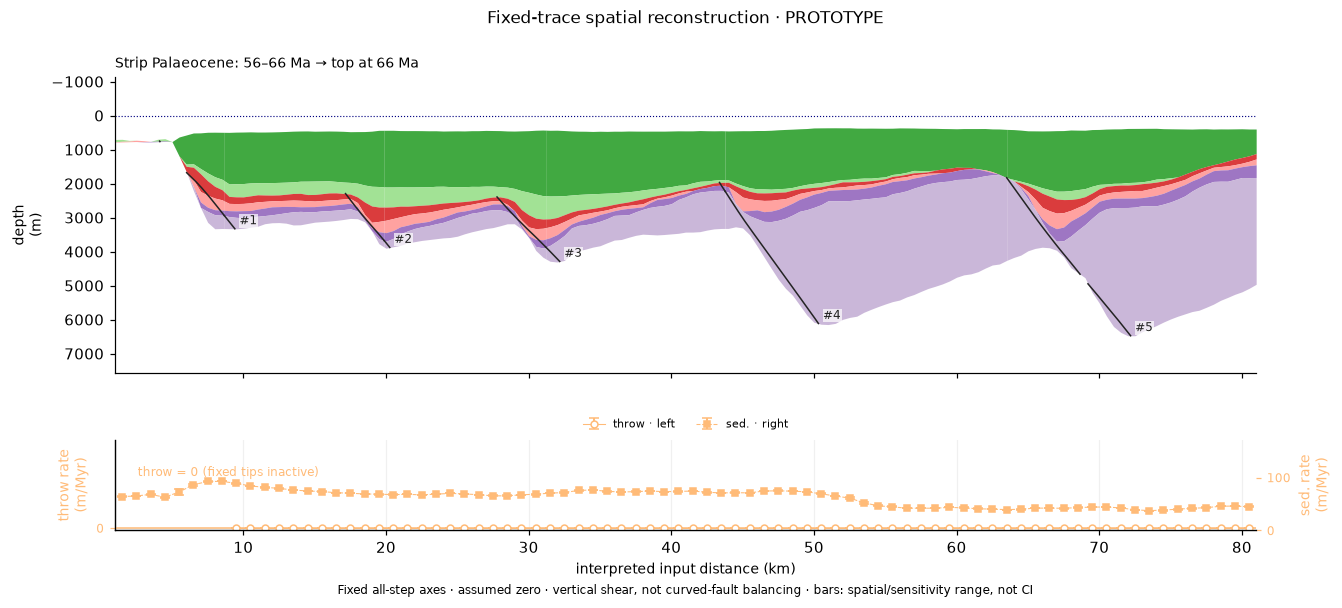

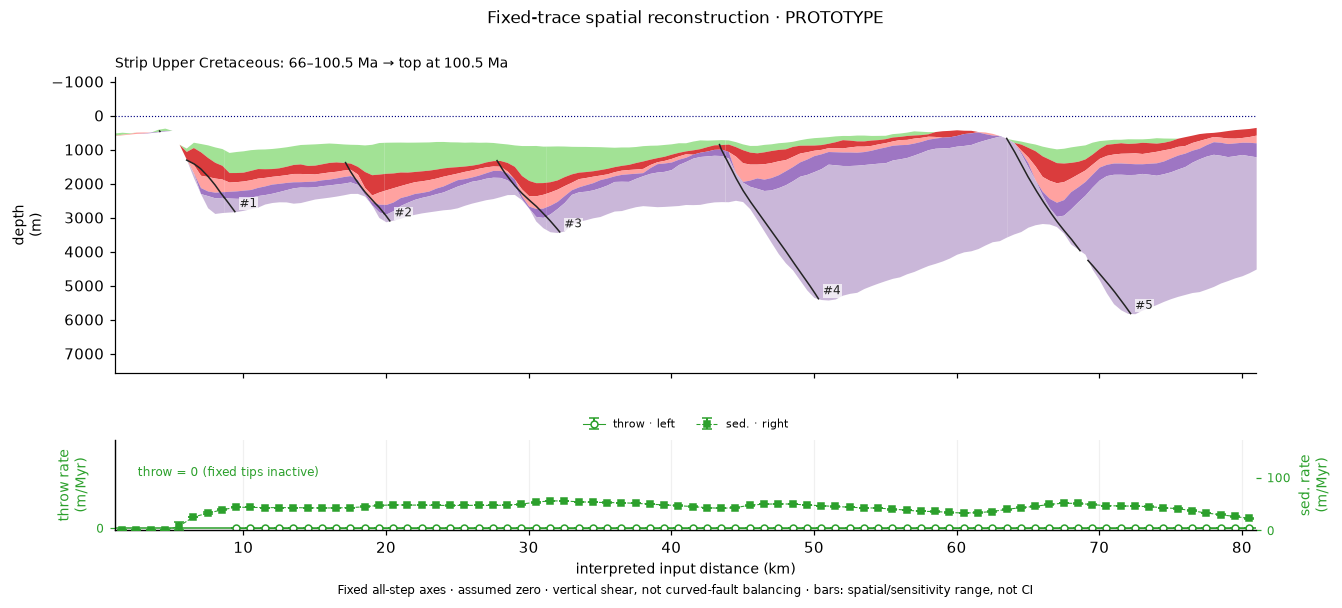

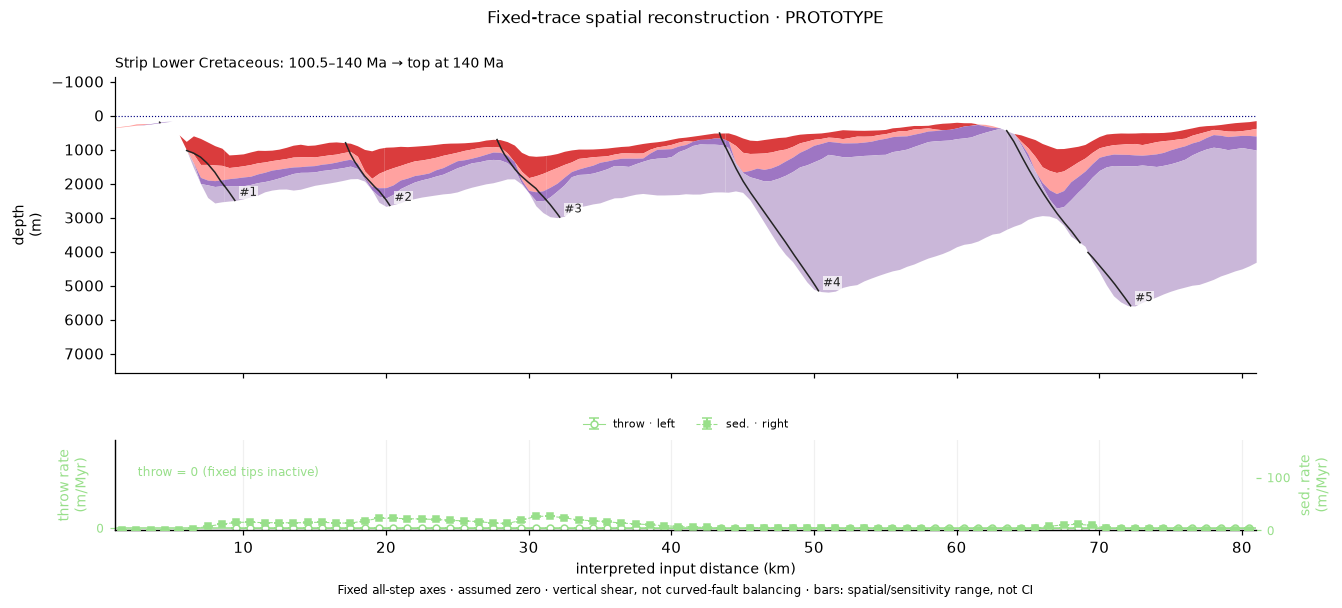

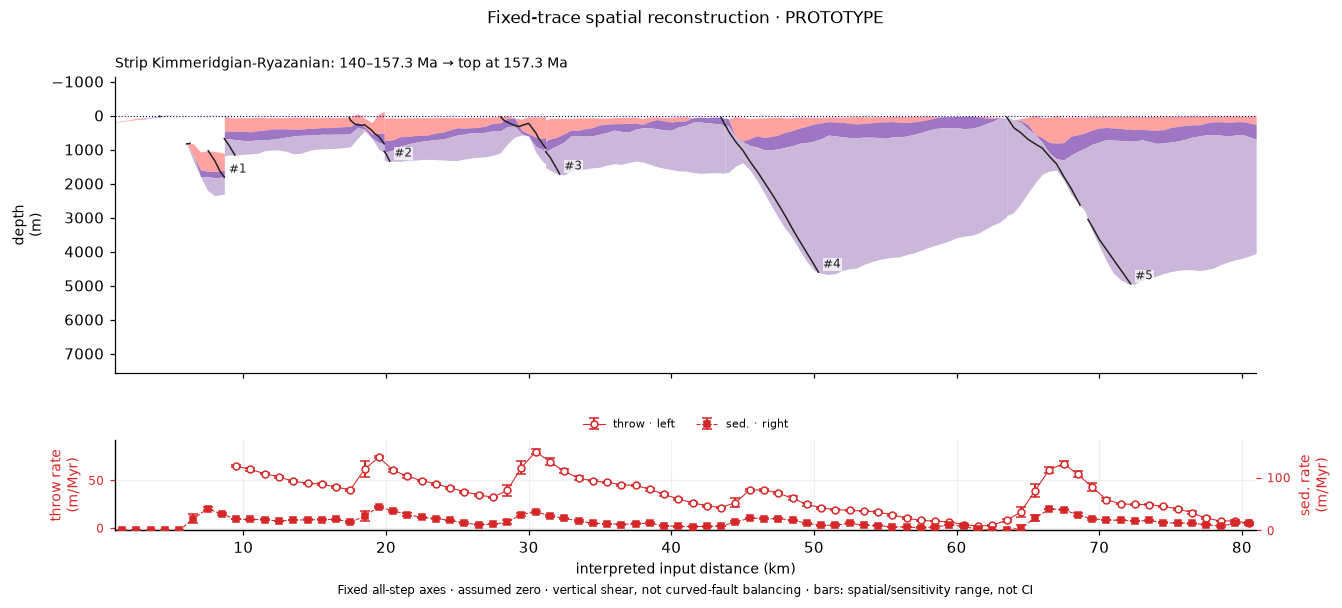

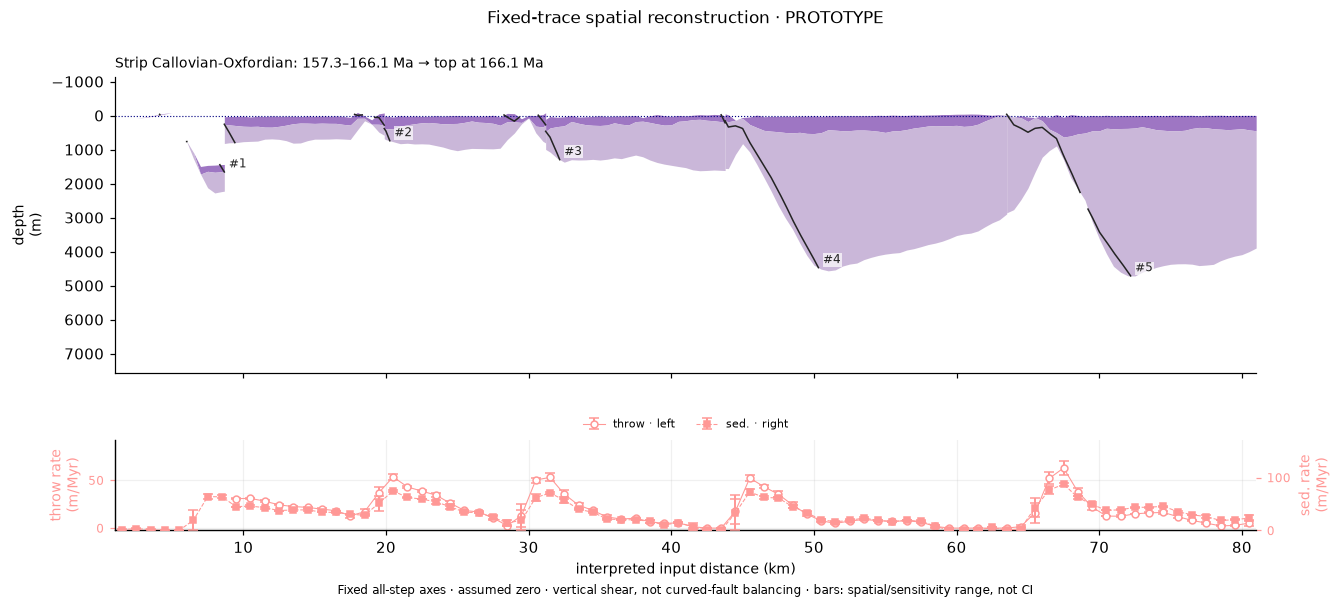

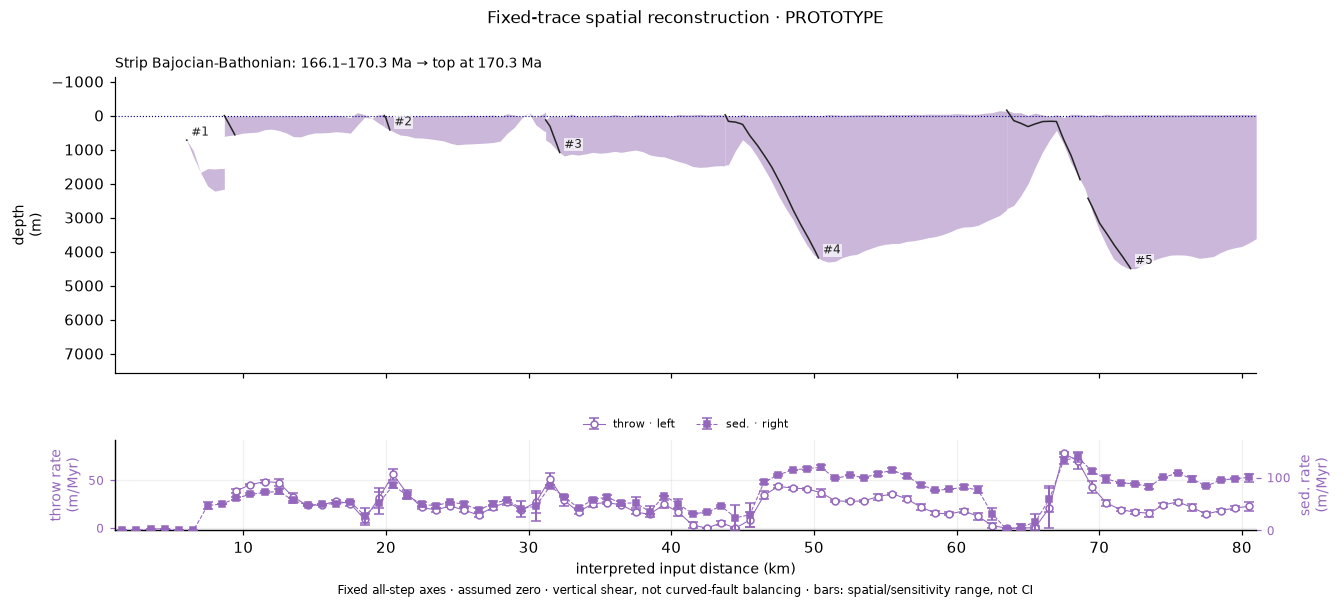

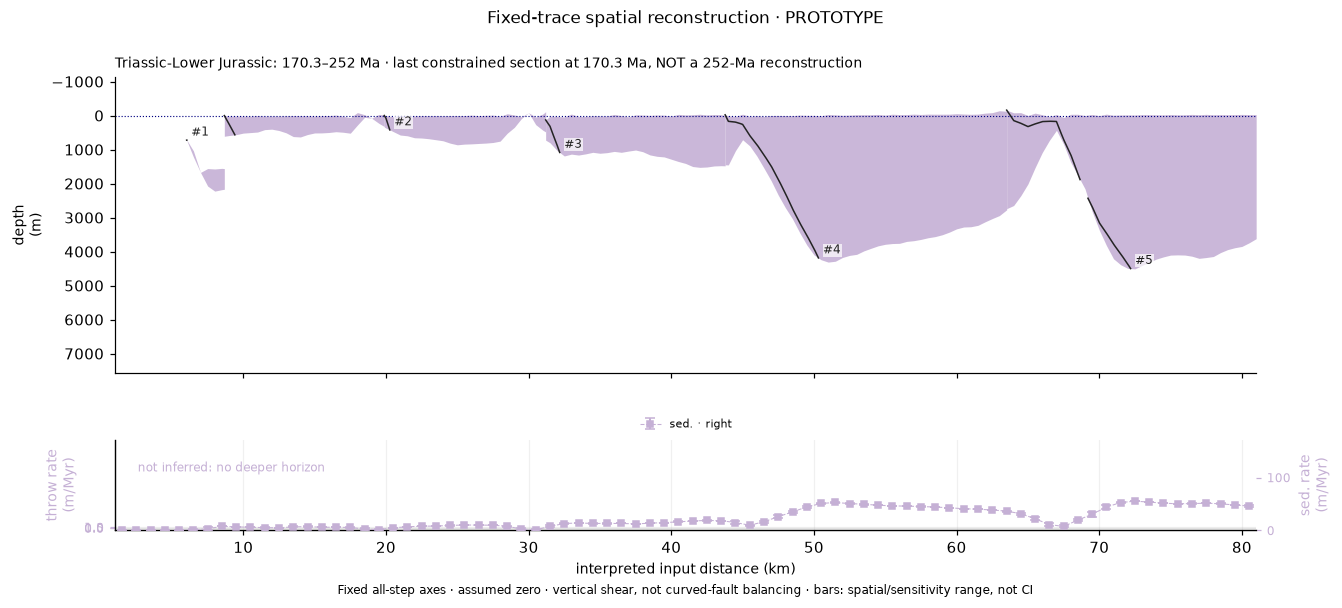

In [4]:
from pybasinsubs.growth_spatial import reconstruct_spatial_growth, binned_spatial_rates
from pybasinsubs.growth_display import plot_growth_frames
# Explicit call: do not reconstruct while loading or inspecting the inputs.
analysis_growth = reconstruct_spatial_growth(analysis_section, analysis_faults, make_figures=False)
analysis_sensitivity = [
    reconstruct_spatial_growth(analysis_section, analysis_faults, make_figures=False,
                              datum_sigma_m=d, growth_sigma_m=g)
    for d, g in [(125., 500.), (175., 700.)]
]
analysis_bins = binned_spatial_rates(analysis_growth, sensitivity=analysis_sensitivity)
# Set show_fault_numbers=False to hide trace numbers. Each figure is one timestep.
for fig in plot_growth_frames(analysis_growth, bins=analysis_bins, show_fault_numbers=True):
    display(fig)
    plt.close(fig)


### 4 · Summary diagnostics and tables

Inferred increments and binned spatial rates are shown after the restored frames. The browser provides a vertical geological-time slider (modern at top), playback and CSV downloads.

In [5]:
display(analysis_growth.history.round(3))
display(analysis_bins.round(3))


,unit,fault,age_top_Ma,age_base_Ma,duration_Myr,throw_m,heave_m,dip_slip_m,rotation_deg,throw_m_Myr,heave_m_Myr,dip_slip_m_Myr,rotation_deg_Myr,rotation_kind,inference,auxiliary_contact_translation_increment_m,auxiliary_contact_translation_m_Myr
0,Pliocene-Recent,F1,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
1,Pliocene-Recent,F2,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
2,Pliocene-Recent,F3,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
3,Pliocene-Recent,F4,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
4,Pliocene-Recent,F5,0.0,5.3,5.3,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
5,Miocene,F1,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
6,Miocene,F2,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
7,Miocene,F3,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
8,Miocene,F4,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0
9,Miocene,F5,5.3,23.0,17.7,0.000,NaN,NaN,NaN,0.000,NaN,NaN,NaN,"not inferred: vertical-shear field, not rigid ...",apparent distributed vertical throw; NOT resol...,0.0,0.0


,unit,x_bin_lo_m,x_bin_hi_m,x_m,kind,rate_m_Myr,range_low_m_Myr,range_high_m_Myr,n,errorbar
0,Pliocene-Recent,1000.0,2000.0,1500.0,sedimentation,67.915,66.830,69.000,2,within-bin spatial + fit-sensitivity range; NO...
1,Pliocene-Recent,2000.0,3000.0,2500.0,sedimentation,69.000,69.000,69.000,2,within-bin spatial + fit-sensitivity range; NO...
2,Pliocene-Recent,3000.0,4000.0,3500.0,sedimentation,69.000,69.000,69.000,2,within-bin spatial + fit-sensitivity range; NO...
3,Pliocene-Recent,4000.0,5000.0,4500.0,sedimentation,67.925,66.849,69.000,2,within-bin spatial + fit-sensitivity range; NO...
4,Pliocene-Recent,5000.0,6000.0,5500.0,sedimentation,66.849,66.849,66.849,2,within-bin spatial + fit-sensitivity range; NO...
...,...,...,...,...,...,...,...,...,...,...
1443,Triassic-Lower Jurassic,76000.0,77000.0,76500.0,sedimentation,50.769,50.495,51.043,2,within-bin spatial + fit-sensitivity range; NO...
1444,Triassic-Lower Jurassic,77000.0,78000.0,77500.0,sedimentation,51.612,51.531,51.693,2,within-bin spatial + fit-sensitivity range; NO...
1445,Triassic-Lower Jurassic,78000.0,79000.0,78500.0,sedimentation,50.348,49.664,51.032,2,within-bin spatial + fit-sensitivity range; NO...
1446,Triassic-Lower Jurassic,79000.0,80000.0,79500.0,sedimentation,48.243,47.927,48.559,2,within-bin spatial + fit-sensitivity range; NO...


## Further method background and validation

The following experiments investigate alternative assumptions; they are separate from the fixed-input prototype above.

## 1 · Auto-detection from horizon offsets

A fault that cuts a horizon leaves a **steep, offset segment** (the fault face between footwall and hangingwall cutoffs). For a cut horizon the middle of that face lies on the fault plane.

1. On every horizon find runs with $|dz/dx| >$ `slope_min` (0.35, ≈ 19°) and throw $T = |z_{end}-z_{start}| >$ `min_throw` (150 m). The point $(x_m, z_m)$ at half the throw is a fault-plane point. The polarity (down = ±1) is the sign of the step.
2. **Link** points into fault sticks, deepest horizon first. A point on the next shallower horizon joins a stick if it has the same polarity and lies within `link_dx` (2.5 km) of the up-dip prediction
$$x_p = x_l - \text{down}\,\frac{z_l - z_m}{\tan\delta_g},\qquad \delta_g = 50°.$$
3. Keep sticks with ≥ 2 horizons. Fit a plane $x = a + b z$ by least squares, giving dip $\delta = \arctan(1/|b|)$ (true scale, so vertical exaggeration does not bias it). The trace x₀ is the stick point on the oldest top (or the intersection of the plane with it). Throws come from `flex2d.fault_at`.
4. Merge sticks of the same polarity whose traces are closer than 1.5 km (one fault picked twice).

$$\text{confidence} = \sqrt{n_{hits}/n_{horizons}}\;e^{-\text{rms}_x/500\,\text{m}},$$
halved if the dip direction from the fit disagrees with the throw polarity or the dip is outside 25–85°.

saved image/nb9_autodetect_horizons.png


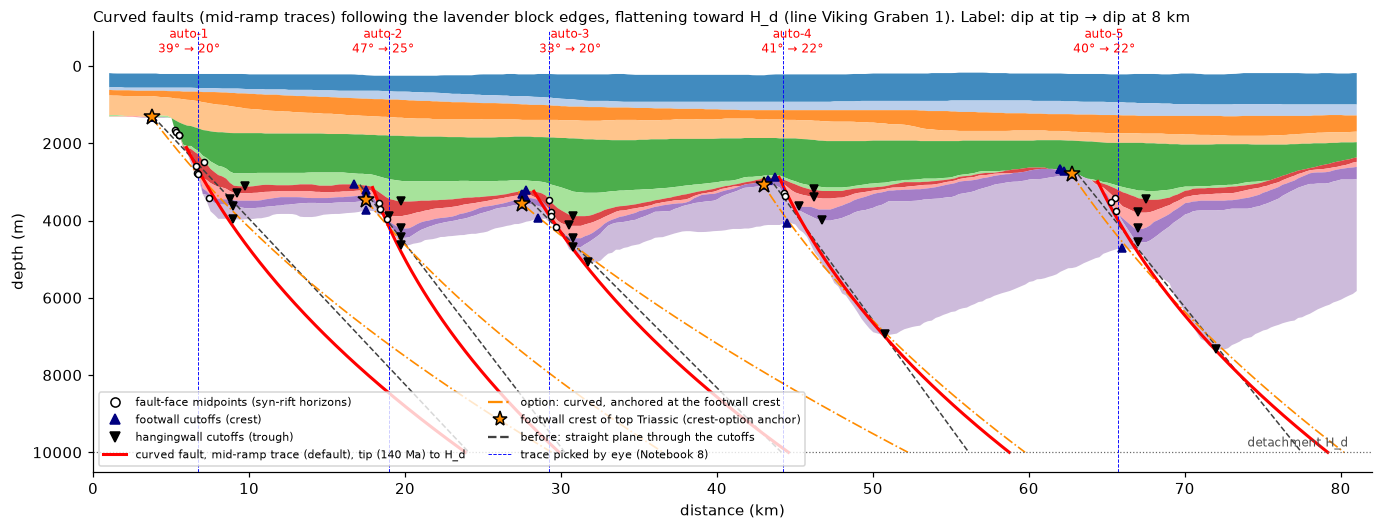

,fault,x0_km,dip_tip,dip_4km,dip_6km,dip_8km,dip_effective,lam_km,x0_crest_km,dip0_crest,dip_up_crest,dip_planar_cutoffs,dip_face_midpoints,top_tip_m,rms_x_m,n_points
0,auto-1,6.2,38.9,30.8,24.3,19.6,34.9,5.9,3.8,28.4,37.9,23.2,37.9,2108.1,289.0,10
1,auto-2,18.6,46.8,42.3,32.5,25.4,42.9,5.9,17.5,26.4,38.8,27.8,38.8,3145.7,172.5,9
2,auto-3,30.6,32.7,30.9,24.3,19.6,30.1,5.9,27.5,18.8,58.8,22.0,58.8,3244.3,292.5,9
3,auto-4,44.8,40.7,35.6,27.5,21.8,31.4,5.7,43.0,32.0,63.6,29.1,63.6,2880.1,223.7,8
4,auto-5,64.8,39.8,35.1,27.3,21.7,30.1,5.9,62.8,30.8,66.0,26.6,66.0,2990.7,293.3,9


,reference,ref_x0_km,det,det_x0_km,dx0_m,ref_dip,det_dip,ddip_deg,confidence
0,margin,6.75,auto-1,6.15,-597.40,45.0,34.86,-10.14,0.64
1,Heather|Pelican,19.00,auto-2,18.60,-404.07,45.0,42.89,-2.11,0.49
2,Pelican|Hutton,29.25,auto-3,30.59,1337.48,45.0,30.14,-14.86,0.54
3,Hutton|Brent,44.25,auto-4,44.84,593.70,45.0,31.39,-13.61,0.45
4,Brent|Gullfaks,65.75,auto-5,64.84,-913.64,45.0,30.06,-14.94,0.41


In [2]:
det_raw, sticks_tab = F.detect_faults_from_horizons(xg, vtops)
# Upper tip = top Kimmeridgian-Ryazanian (140 Ma, base of the post-rift): faults do not cut the Cretaceous or younger units.
TIP = 6
HD = 10e3                                          # detachment depth: the curved traces end (flatten) there
# (a) straight planes through the pre-rift block cutoffs (previous version, kept for comparison)
det_planar = F.faults_from_cutoffs(det_raw, xg, vtops, vbase, tip_unit=TIP)
# (b) CURVED traces fitted through all constraints ordered by depth: face midpoints of the syn-rift horizons
#     (shallow, steep), fw/hw block cutoffs incl. top and base Triassic (the lavender block edges), flattening to H_d
#     Default trace_anchor='midramp': free fit, the trace crosses top Triassic in the middle of the drawn fault ramp
det = F.faults_from_curves(det_raw, xg, vtops, vbase, tip_unit=TIP, Hd=HD)
det_mid = det                                      # alias (mid-ramp = default)
# (c) option trace_anchor='footwall_crest': curve forced through the footwall-crest cutoff of top Triassic
det_crest = F.faults_from_curves(det_raw, xg, vtops, vbase, tip_unit=TIP, Hd=HD, trace_anchor="footwall_crest")
VAL = F.compare_faults(det, vfaults)
fig, ax = plt.subplots(figsize=(15, 5.2)); draw_section(ax)
FF.plot_fault_planes(ax, det_planar, HD, "planar", xg, vtops, labels=False, color="0.25", lw=1, ls="--")
FF.plot_fault_planes(ax, det_crest, HD, "planar", xg, vtops, labels=False, color="darkorange", lw=1.1, ls="-.")
FF.plot_fault_planes(ax, det, HD, "planar", xg, vtops, labels=False, color="r", lw=2)
for f, g in zip(det, sorted(det_raw, key=lambda f: f.x0)):
    t = f.cutoffs["table"]; s = np.asarray(g.stick)
    ax.plot(t.x_fw / 1e3, t.z_fw, "^", color="navy", ms=5, zorder=6); ax.plot(t.x_hw / 1e3, t.z_hw, "v", color="k", ms=5, zorder=6)
    ax.plot(s[:, 0] / 1e3, s[:, 1], "o", color="w", mec="k", ms=4, zorder=7)
for f in det_crest:
    xa, za = f.curve_params["anchor"]; ax.plot(xa / 1e3, za, "*", color="darkorange", mec="k", ms=11, zorder=8)
for f in det:
    ax.text(f.x0 / 1e3, -350, f"{f.label}\n{f.dip_at(f.z_tip):.0f}° → {f.dip_at(8e3):.0f}°", color="r", fontsize=8, ha="center")
ax.axhline(HD, color="0.4", lw=.8, ls=":"); ax.text(80.5, HD - 150, "detachment H_d", fontsize=8, ha="right", color="0.3")
ax.set_ylim(HD + 500, -900); ax.set_xlim(0, 82)
for f in vfaults: ax.axvline(f.x0 / 1e3, color="b", lw=.6, ls="--")
ax.plot([], [], "o", color="w", mec="k", label="fault-face midpoints (syn-rift horizons)")
ax.plot([], [], "^", color="navy", label="footwall cutoffs (crest)"); ax.plot([], [], "kv", label="hangingwall cutoffs (trough)")
ax.plot([], [], "r-", lw=2, label="curved fault, mid-ramp trace (default), tip (140 Ma) to H_d")
ax.plot([], [], "-.", color="darkorange", label="option: curved, anchored at the footwall crest")
ax.plot([], [], "*", color="darkorange", mec="k", ms=10, label="footwall crest of top Triassic (crest-option anchor)")
ax.plot([], [], "--", color="0.25", label="before: straight plane through the cutoffs")
ax.plot([], [], "b--", lw=.6, label="trace picked by eye (Notebook 8)")
ax.legend(fontsize=7.5, loc="lower left", ncol=2)
ax.set_title("Curved faults (mid-ramp traces) following the lavender block edges, flattening toward H_d (line Viking Graben 1). Label: dip at tip → dip at 8 km", loc="left", fontsize=10)
save(fig, "nb9_autodetect_horizons.png"); plt.show()
FTAB = pd.DataFrame([dict(fault=f.label, x0_km=f.x0 / 1e3, dip_tip=f.dip_at(f.z_tip), dip_4km=f.dip_at(4e3), dip_6km=f.dip_at(6e3),
                          dip_8km=f.dip_at(8e3), dip_effective=f.dip, lam_km=f.curve_params["lam"] / 1e3,
                          x0_crest_km=k.x0 / 1e3, dip0_crest=k.curve_params["dip0"], dip_up_crest=k.curve_params["dip_up"],
                          dip_planar_cutoffs=p.dip, dip_face_midpoints=g.dip, top_tip_m=f.z_tip, rms_x_m=f.curve_params["rms_x"],
                          n_points=f.curve_params["n"])
                     for f, p, g, k in zip(det, det_planar, sorted(det_raw, key=lambda f: f.x0), det_crest)])
display(FTAB.round(1))
VAL.round(2)


**Curved fault traces (current).** A normal fault is rarely a straight line: it is steepest near its upper tip and flattens with depth toward a detachment. A single straight plane is a compromise. The face-midpoint planes (first version) matched the steep faces of the syn-rift horizons. The straight planes through the block cutoffs (second version, dashed) followed the deep block edges but were too gentle at shallow depth, e.g. for the two western faults (~4 and ~18 km), whose steep faces dip ~38–39°. Each fault is now a **curve** whose dip decreases exponentially with depth:

$$\delta(z)=\delta_\infty+(\delta_0-\delta_\infty)\,e^{-(z-z_r)/\lambda},\qquad x(z)=x_r+\mathrm{down}\int_{z_r}^{z}\cot\delta(z')\,dz'$$

- $z_r$: depth of the shallowest constraint; $\delta_0$: dip there; $\lambda$: depth scale of the flattening; $\delta_\infty$ = 8°: limiting dip near the detachment (fixed).
- $x(z)$ is integrated numerically. Because $\delta$ only decreases, depth increases monotonically along the trace and it never overturns.
- **Constraints, ordered by depth**:
  1. the face midpoints of the syn-rift horizons below the tip (shallow, steep part);
  2. per horizon, the midpoint of its footwall/hangingwall cutoff pair (the window-picked cutoffs straddle the fault), for the syn-rift and pre-rift tops and the base of the Triassic;
  3. the deepest hangingwall cutoff (base Triassic, the bottom corner of the lavender block).
  Cutoffs flattened onto the crest at the tip horizon are dropped.
- **Fit**: weighted least squares in x for $(x_r,\delta_0,\lambda)$ (`scipy.optimize.least_squares`), with $\delta_0$ in 10–70°. Cutoffs are weighted by throw, face midpoints by the median cutoff throw. A weak log-normal prior, $\ln\lambda \sim N(\ln 6\,\mathrm{km},\,0.5)$, stops 1–3 km of constraints from bending the curve into a kink. The parameter covariance $s^2(J^TJ)^{-1}$ is kept for the Monte Carlo.
- **Trace position (default `trace_anchor='midramp'`)**: no anchor; all three parameters are fitted freely and the trace $x_0$ is where the curve meets top Triassic, in the middle of the drawn fault ramp (red). Option `trace_anchor='footwall_crest'` (orange dash-dot, stars) forces the curve exactly through the footwall-crest cutoff of top Triassic, with a straight segment at the syn-rift face dip above it; it treats the drawn ramp as a hangingwall fold. The straight planes (`faults_from_cutoffs`, grey dashed) and the face-midpoint planes (`detect_faults_from_horizons`) remain available.
- **Tip**: the curve starts where it meets the top of the syn-rift (140 Ma). If it would rise above that horizon down-dip, the tip moves down until it stays below. Throws are re-measured there and set to zero for units at and above the tip.

**How each restoration uses the curve**
- **Listric** (inclined shear): uses the curve itself as the fault surface $z_f(x)$, translated vertically to pass through the restored horizon at the trace.
- **Cantilever**: uses the local dip $\delta(z)$ where the curve crosses the trace depth, for the heave $e=s/\tan\delta$ and the ramp. The width of the collapsing hangingwall is $L=|x(H_d)-x_0|$ (the curve's reach to the detachment, limited by the block width), instead of $H_d/\tan\delta$.
- **Domino** (rigid blocks, planar by construction): uses the **effective planar dip** of the block-bounding segment, i.e. the chord from the upper tip to the deepest hangingwall cutoff (base of the pre-rift block). This is `Fault.dip` of a curved fault.
- **User sticks**: imported or hand-traced sticks (`source` 'imported…' or 'traced…') pass through unchanged as the curve, extended below their deepest point at their last dip.

The table gives, for each fault: the dip at the tip and at 4, 6 and 8 km, the effective (domino) dip, and the crest-option and straight-plane alternatives.

**Mid-ramp dips.** The curves start at 33–47° at the tip and flatten to ~20–25° at 8 km (fault 1: 38.9° → 19.6°; fault 2: 46.8° → 25.4°; fault 3: 32.7° → 19.6°; fault 4: 40.7° → 21.8°; fault 5: 39.8° → 21.7°); effective dips 30–43°. The two western faults keep their steep shallow faces (~39° and ~47°) and bend gently with depth, as in the earlier hand picks.

**Trace positions compared with the picks by eye.** The mid-ramp traces (6.2, 18.6, 30.6, 44.8, 64.8 km) lie within 0.4–1.3 km of the Notebook 8 picks (6.75, 19.0, 29.25, 44.25, 65.75 km). The crest option puts them 1.25–3.0 km further west (3.8, 17.5, 27.5, 43.0, 62.8 km). `ddip_deg` in the comparison table is again the difference from the *assumed* 45°.

**Your own fault surfaces.** Run `pybasinsubs-tracer` to draw, drag, insert/delete nodes, rename, delete and reset faults (reset to curved mid-ramp, curved crest, straight, last saved, or empty) and **Save** them as JSON (default, `pybasinsubs/example_data/faults/vg1_user_faults.json`: version, section_id, units, vertical exaggeration, and per fault id, name, tip_unit, method_origin and the nodes [[x, z], ...], plus created/modified metadata) or CSV (`vg1_user_faults.csv`); **Load** reloads either. Every edit is autosaved to `vg1_user_faults.autosave.json`. With `FAULTS_SOURCE = "user"` (below) this notebook then restores with your faults; while that file does not exist it uses the auto curved mid-ramp faults.

**What this check can and cannot show.** There is no measured dip to compare with. Roberts et al. (1998) Fig. 4a is a depth section at about 4× vertical exaggeration, and the 45° in Notebook 8 was an assumption, so `ddip_deg` is the difference from that assumption, **not an error**. The dips are computed in true scale.


In [3]:
# Fault source for the restorations below: "user" = the stored user file if present
# (vg1_user_faults.json, else .csv; else auto), "auto" /
# "curved_midramp" / "curved_crest" / "straight" = the automatic estimates, or a path to a fault file (.json / .csv / sticks).
FAULTS_SOURCE = "user"
det_auto = det
if FAULTS_SOURCE in ("auto", "curved_midramp") or (FAULTS_SOURCE == "user" and F.stored_user_faults() is None):
    FAULTS_USED = "auto (curved mid-ramp)"
else:
    det, FAULTS_USED = F.load_faults(FAULTS_SOURCE, xg, vtops, vbase, tip_unit=TIP, Hd=HD)
print("faults used for the restorations:", FAULTS_USED, "-", [f"{f.label} @ {f.x0 / 1e3:.1f} km" for f in det])
# The editor is the browser app: run pybasinsubs-tracer. Save there, then re-run this cell.


faults used for the restorations: auto (curved mid-ramp) - ['auto-1 @ 6.2 km', 'auto-2 @ 18.6 km', 'auto-3 @ 30.6 km', 'auto-4 @ 44.8 km', 'auto-5 @ 64.8 km']


## 2 · Auto-detection from a section image (Canny + Hough)

For a scanned or exported section image (`detect_faults_from_image(img, extent, x, tops)`):

1. Grey scale, then **Canny** edges (σ = 2; Canny 1986).
2. **Progressive probabilistic Hough** line segments (Matas et al. 2000), as implemented in scikit-image (van der Walt et al. 2014).
3. Pixel end points are converted to metres with `extent` = (x_min, x_max, z_max, z_min). The segment dip is then the **true-scale** dip $\arctan|\Delta z/\Delta x|$, which removes the vertical exaggeration of the image. Segments with dips of 25–85° are kept (flat layer boundaries and vertical image edges are rejected).
4. Segments are clustered by mid-x (2 km) and dip direction into sticks.
5. **Horizon-offset alignment**: if horizons are supplied, a cluster is kept only where the oldest horizon steps down by ≥ 150 m across it.

confidence = min(1, n_segments/6) · (0.5 + 0.5·offset confirmed).

The published raster of Roberts et al. (1998) Fig. 4a is not stored in the repository. The detector has therefore been tested **only on a rendering of the digitized section, not on the real scan**, at the same 4× vertical exaggeration as the original figure. On a real scan, labels, well symbols and seismic texture would produce more spurious edges.

saved image/nb9_autodetect_image.png


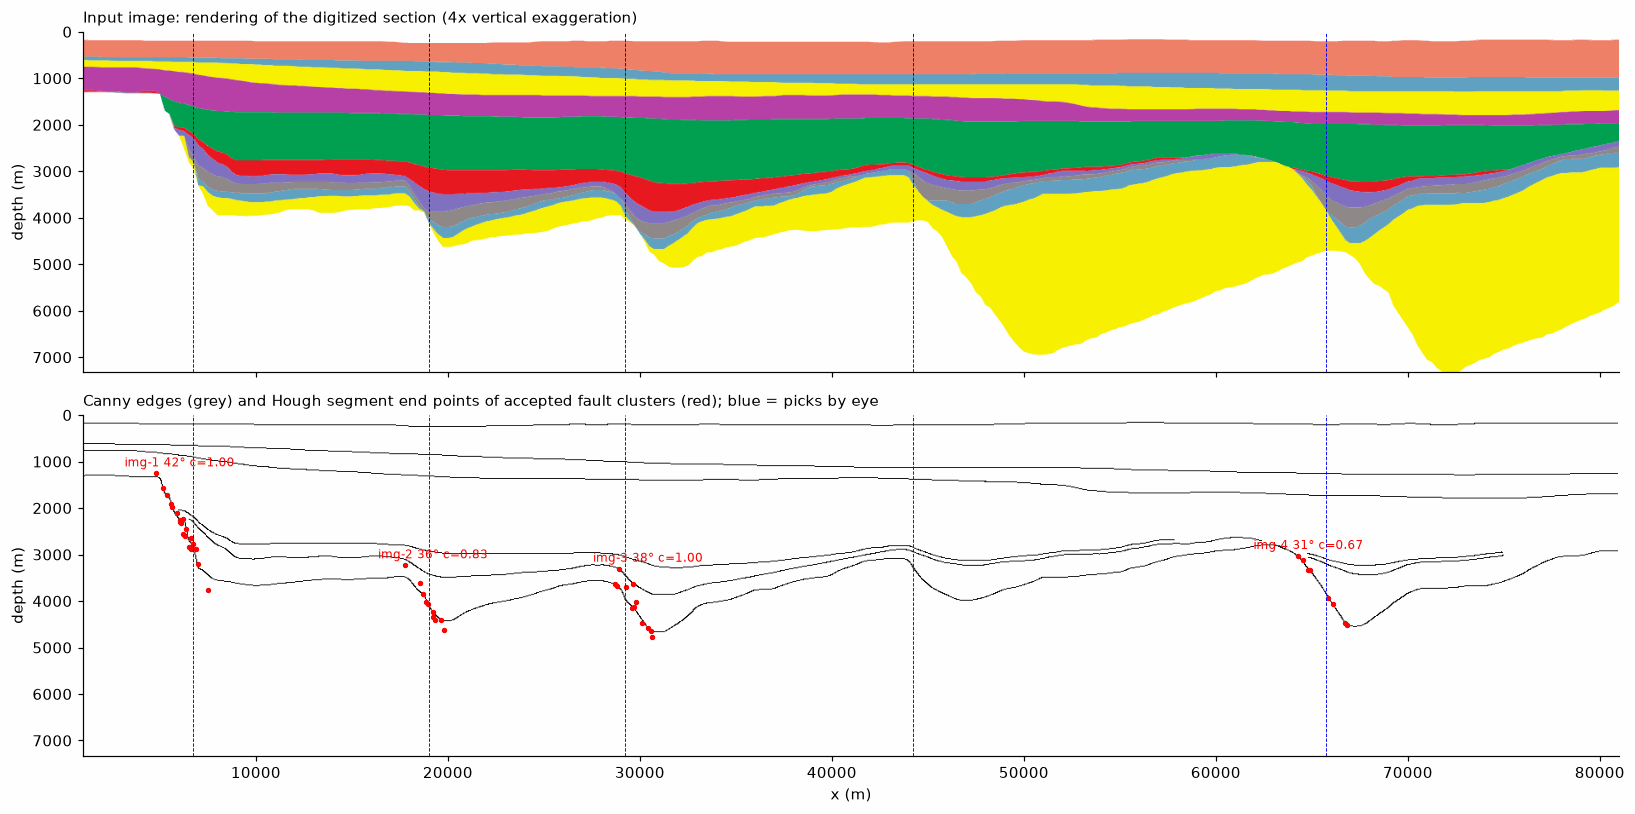

,reference,ref_x0_km,det,det_x0_km,dx0_m,ref_dip,det_dip,ddip_deg,confidence
0,margin,6.75,img-1,6.02,-725.0,45.0,41.93,-3.07,1.00
1,Heather|Pelican,19.00,img-2,19.23,225.0,45.0,36.46,-8.54,0.83
2,Pelican|Hutton,29.25,img-3,30.42,1175.0,45.0,37.92,-7.08,1.00
3,Hutton|Brent,44.25,MISSED,NaN,NaN,NaN,NaN,NaN,NaN
4,Brent|Gullfaks,65.75,img-4,64.82,-925.0,45.0,30.86,-14.14,0.67


In [4]:
img, ext = F.render_section_image(xg, vtops, vbase, colors=DETECTION_COLORS, px=(1600, 400))
deti = F.detect_faults_from_image(img, ext, xg, vtops)
from skimage import color, feature
edges = feature.canny(color.rgb2gray(img), sigma=2.0)
fig, ax = plt.subplots(2, 1, figsize=(15, 7.5), sharex=True)
ax[0].imshow(img, extent=ext, aspect="auto"); ax[0].set_title("Input image: rendering of the digitized section (4x vertical exaggeration)", loc="left", fontsize=10)
ax[1].imshow(edges, extent=ext, aspect="auto", cmap="gray_r")
for f in deti:
    ax[1].plot(f.stick[:, 0], f.stick[:, 1], "r.", ms=5)
    ax[1].text(f.x0, f.stick[:, 1].min() - 150, f"{f.label} {f.dip:.0f}° c={f.confidence:.2f}", color="r", fontsize=8, ha="center")
for f in vfaults:
    for a_ in ax: a_.axvline(f.x0, color="b", lw=.6, ls="--")
ax[1].set_title("Canny edges (grey) and Hough segment end points of accepted fault clusters (red); blue = picks by eye", loc="left", fontsize=10)
for a_ in ax: a_.set_ylabel("depth (m)")
ax[1].set_xlabel("x (m)"); fig.tight_layout(); save(fig, "nb9_autodetect_image.png"); plt.show()
F.compare_faults(deti, vfaults).round(2)

On the rendered image (not a real scan) the image detector also finds all five faults. Its trace positions are less accurate (≈ 0.1–1.1 km), because the Hough segments follow the whole steep face and the edges of neighbouring layers rather than the face midpoint. Its dips are lower (≈ 25–44°), because steep layer-boundary edges near the faces are mixed into the clusters. The horizon-offset detector is used for the restorations below; the image detector is useful when only a picture of the section exists.

The image-detection figure deliberately retains the frozen legacy RGB raster seen by Canny/Hough. Other VG1 displays use the shared app palette; display colors never enter this detector input.

## 3 · Synthetic test with known faults

Two planar faults at 20 and 50 km, true dip 55°, 600 m throw on four horizons. The same check runs in `tests/test_generic.py`.

In [5]:
def synthetic(x0s=(20e3, 50e3), dip=55.0, throw=600.0):
    x = np.arange(0, 80e3, 100.0); tops = []
    for z0 in [1500.0, 2200.0, 3000.0, 3800.0]:
        z = np.full_like(x, z0)
        for xf in x0s:
            xc = xf + (z0 - 1500.0) / np.tan(np.radians(dip)); h = 0.5 * throw / np.tan(np.radians(dip))
            z = z + np.clip((x - (xc - h)) / (2 * h), 0, 1) * throw
        tops.append(z)
    return x, np.array(tops)
xs_, ts_ = synthetic()
truth = [flex2d.Fault(x0=xf, dip=55.0, down=1, throw=np.zeros(4), label=f"true {xf/1e3:g} km") for xf in (20e3, 50e3)]
d_h, _ = F.detect_faults_from_horizons(xs_, ts_, ref=0)
im_s, ex_s = F.render_section_image(xs_, ts_, ts_[-1] + 800, extent_z=(1000, 5000))
d_i = F.detect_faults_from_image(im_s, ex_s, xs_, ts_, ref=0)
pd.concat([F.compare_faults(d_h, truth).assign(detector="horizon offsets"),
           F.compare_faults(d_i, truth).assign(detector="image (Canny+Hough)")]).round(2)

,reference,ref_x0_km,det,det_x0_km,dx0_m,ref_dip,det_dip,ddip_deg,confidence,detector
0,true 20 km,20.0,auto-1,20.00,0.00,55.0,55.00,-0.00,1.0,horizon offsets
1,true 50 km,50.0,auto-2,50.00,0.00,55.0,55.00,0.00,1.0,horizon offsets
0,true 20 km,20.0,img-1,20.20,199.72,55.0,61.00,6.00,1.0,image (Canny+Hough)
1,true 50 km,50.0,img-2,50.21,212.16,55.0,54.76,-0.24,1.0,image (Canny+Hough)


Where the answer is known, the horizon detector recovers trace position and dip closely. The image detector finds both faults, with larger position and dip errors.

## 4 · Importing fault sticks

`F.read_fault_sticks(path, fmt="auto", columns=None, line=None)` returns `{fault_id: array([[x, z], ...])}`. `F.sticks_to_faults(sticks, x, tops)` then gives Fault objects (planar dip from each stick, trace on the oldest top, throws). Example files are in `pybasinsubs/example_data/faults/` (`data_path("faults")`). They were generated from the auto-detected VG1 sticks; their map coordinates are **synthetic** (the line is placed due east from 450000 E, 6720000 N).

| format (`fmt`) | layout (one point per line) | example file |
|---|---|---|
| `csv` | header `fault_id,x,z` (m; z = depth, positive down); optional `y` (projected with `line`), `stick`, `x_km`/`z_km` | `vg1_fault_sticks.csv` |
| `geojson` | FeatureCollection of LineString/MultiLineString; id from `fault_id`/`name`/`id`; coordinates `[x, z]` (section) or `[x, y, z]` (map + depth, needs `line`) | `vg1_fault_sticks.geojson` |
| `petrel_charisma` | `INLINE- <il> <xl> <x> <y> <z> <fault_name> <stick>` (Petrel "Charisma fault sticks" style) | `vg1_fault_sticks_petrel_charisma.txt` |
| `kingdom` | `x y z fault_name segment` (assumed simple layout) | `vg1_fault_sticks_kingdom.txt` |
| `opendtect` | FaultStickSet ASCII `x y z stick_index`, `#` comments; one fault per file (id = file name) | `vg1_F3_opendtect_faultstickset.txt` |

Map points (x, y) are projected onto the section line `line=((x0, y0), (x1, y1))`: $d = (\mathbf p - \mathbf p_0)\cdot \hat{\mathbf u}$.

**Caveats.** The Petrel, Kingdom and OpendTect readers are **untested on real exports** from those programs: they are tested only on the example files written by this package. Vendor exports vary between versions and settings. These are simple parsers for the layouts above; pass `columns=[...]` (from `x, y, z, fault_id, stick, skip`) for other orders. They are tested against the example files, **not against real Petrel/Kingdom/OpendTect exports**. Depth must be in metres: convert TWT with a velocity model first (`z_sign=-1` for elevations). Points far from the section line are projected without any distance filter.

In [6]:
L = ((450000.0, 6720000.0), (460000.0, 6720000.0)); EX = data_path("faults")
rows = []
for fn in sorted(os.listdir(EX)):
    s = F.read_fault_sticks(os.path.join(EX, fn), line=L)
    fs_ = F.sticks_to_faults(s, xg, vtops)
    rows.append(dict(file=fn, faults=len(s), points=sum(len(v) for v in s.values()),
                     x0_km=", ".join(f"{f.x0/1e3:.1f}" for f in fs_), dips=", ".join(f"{f.dip:.0f}" for f in fs_)))
pd.DataFrame(rows)

,file,faults,points,x0_km,dips
0,vg1_F3_opendtect_faultstickset.txt,1,4,29.7,59
1,vg1_fault_sticks.csv,5,21,"7.5, 18.8, 29.7, 44.4, 65.6","38, 39, 59, 64, 66"
2,vg1_fault_sticks.geojson,5,22,"6.7, 18.8, 29.7, 44.4, 65.6","38, 39, 59, 64, 66"
3,vg1_fault_sticks_kingdom.txt,5,22,"6.7, 18.8, 29.7, 44.4, 65.6","38, 39, 59, 64, 66"
4,vg1_fault_sticks_petrel_charisma.txt,5,22,"6.7, 18.8, 29.7, 44.4, 65.6","38, 39, 59, 64, 66"


## 5 · Interactive manual tracing (several faults)

**In the browser.** Run `pybasinsubs-tracer` (= `pybasinsubs-app --page faults`). The page shows the section image with the five auto-detected faults as a dashed background, and your own faults on top.

- **Draw:** click nodes along a fault, then **Finish** (or double-click, or Enter). Backspace removes the last node. One polyline = one fault stick; several nodes make a curved stick.
- **Select:** click a fault, drag its nodes. **Insert node**, **Delete node**, **Rename**, **Tip horizon** (the horizon whose top is the upper tip) and **Delete fault** act on the selected fault.
- **Undo / Redo**, and **Reset to** curved mid-ramp, curved crest, straight, last saved, or empty. Every edit is autosaved.
- **Save / Load / Download** as JSON (default) or CSV; **Import** reads CSV, GeoJSON or Petrel / Kingdom / OpendTect ASCII sticks.
- **Run restoration:** pick cantilever, listric or domino, T_e and H_d. The restored section and the flatness metrics appear under the editor.

**From code (this notebook).** The next cell uses the same `FaultTracer` object the app uses, without a browser: `tracer.sticks()`, `tracer.faults()`, `tracer.run_restoration("listric", Te=1500, Hd=8e3)` and `tracer.to_csv(path)` return ordinary objects, so traced faults can be used in any later cell.

![Browser fault editor and restored oldest horizon](../image/app_fault_editor.png)
*The separate browser app on the bundled Viking Graben section: editable x–depth sticks and a domino-restoration preview (T_e = 1.5 km, H_d = 8 km). The restored pre-rift surface is not flat. Save faults in the app, then reload them in the notebook; there is no embedded browser editor.*


domino (Te 1500 m, H_d 8 km), 5 faults - restored 170.3 Ma top: std 763 m, P95-P5 relief 2150 m (flatter = better)


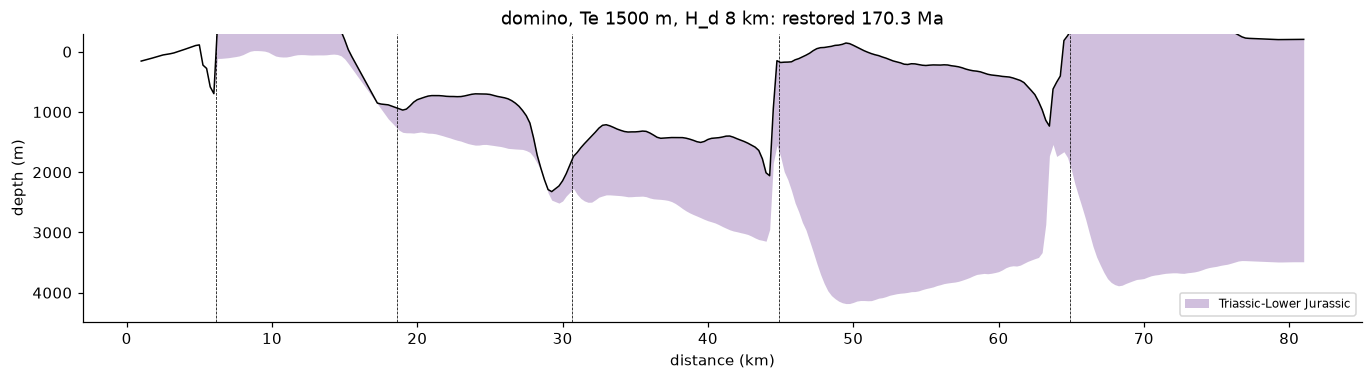

In [7]:
from pybasinsubs.fault_tracer import FaultTracer
display_img, display_ext = F.render_section_image(xg, vtops, vbase, colors=VCOL, px=(1600, 400))
tracer = FaultTracer(vsec, vtops, image=display_img, extent=display_ext, faults=det, colors=VCOL)
fig, metrics, msg = tracer.run_restoration("domino", Te=1500.0, Hd=8e3)   # what the app's "Run restoration" button does
print(msg)
fig

## 6 · Restoration with the auto-detected fault geometry (all three methods)

Same sequence and parameters as Notebook 8: T_e = 1.5 km, β = 1.15, rift end 155 Ma, faults inactive after 140 Ma; cantilever H_d = 8 km; listric H_d = 10 km with inclined shear α = 65°. **Prior** = Notebook 8 geometry: traces picked by eye, planar dip 45° assumed, listric dips fitted to the fault faces. **Auto** = horizon-offset detection: its traces and planar dips, and listric near-surface dips fitted to the detected sticks (`fit_listric_stick`). Metrics are for the top Triassic–Lower Jurassic at 170.3 Ma, and the fault offset is measured at the picks by eye for both, so the comparison is like for like.

In [8]:
RUNS = {}
for meth, kw in [("cantilever", dict(Hd=8e3)), ("listric", dict(alpha=65.0)), ("domino", {})]:
    for geo, FS in [("prior", vfaults), ("auto", det)]:
        RUNS[(meth, geo)] = flex2d.restore(vsec, FS, method=meth, Te=1500.0, beta=1.15, rift_end_Ma=155.0, fault_end_Ma=140.0, **kw)
r0 = flex2d.restore(vsec, [], method="cantilever", Te=1500.0, beta=1.15, rift_end_Ma=155.0, fault_end_Ma=140.0)
A0 = flex2d.layer_areas(r0, 9)[9]
rows = [dict(method="no fault restoration", geometry="-", **{k: v for k, v in flex2d.restoration_metrics(r0, 9, xg, vfaults).items()}, area_change_pct=0.0)]
for (meth, geo), r in RUNS.items():
    m = flex2d.restoration_metrics(r, 9, xg, vfaults)
    rows.append(dict(method=meth, geometry=geo, **m, area_change_pct=100 * (flex2d.layer_areas(r, 9)[9] / A0 - 1)))
MET9 = pd.DataFrame(rows); MET9.round(1)

,method,geometry,std,relief_p95_p5,max_relief,mean_fault_offset,roughness,area_change_pct
0,no fault restoration,-,536.6,1756.3,2236.6,1235.7,85.6,0.0
1,cantilever,prior,425.4,1402.9,2742.3,650.4,144.2,7.2
2,cantilever,auto,525.4,1765.3,3032.8,750.2,274.5,9.8
3,listric,prior,466.4,1592.1,2203.4,933.8,154.4,10.5
4,listric,auto,656.1,2290.8,2880.1,528.8,202.8,15.6
5,domino,prior,396.7,1135.7,1830.8,489.7,148.9,3.0
6,domino,auto,738.5,2117.5,2975.9,770.2,132.7,5.2


In [9]:
fig, axs = plt.subplots(2, 3, figsize=(20, 6.5), sharex=True, sharey=True)
for c, meth in enumerate(["cantilever", "listric", "domino"]):
    for rr, geo in enumerate(["prior", "auto"]):
        r = RUNS[(meth, geo)]; a_ = axs[rr, c]; i = 9
        a_.fill_between(xg / 1e3, 0, r["seafloor"][i], color="#d8ecf7", lw=0)
        a_.fill_between(xg / 1e3, r["top"][i][i], r["base"][i][i], color=VCOL[i], lw=0)
        for f in (vfaults if geo == "prior" else det): a_.axvline(f.x0 / 1e3, color="k", lw=.5, ls="--")
        m = MET9[(MET9.method == meth) & (MET9.geometry == geo)].iloc[0]
        a_.set_title(f"{meth}, {geo} geometry: std {m['std']:.0f} m, offset {m['mean_fault_offset']:.0f} m", fontsize=10)
        a_.axhline(0, color="navy", lw=.5); a_.set_ylim(5500, -1000)
        if c == 0: a_.set_ylabel("depth (m)")
for a_ in axs[-1]: a_.set_xlabel("distance (km)")
fig.suptitle("Top Triassic-Lower Jurassic restored to 170.3 Ma: prior (picked, 45° assumed) vs auto-detected fault geometry. All fault geometry ESTIMATED.", fontsize=11)
fig.tight_layout(); save(fig, "nb9_restoration_auto_vs_prior.png"); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
lab = [f"{a} / {b}" for a, b in zip(MET9.method, MET9.geometry)]
for a_, k in zip(ax, ["std", "mean_fault_offset"]):
    a_.barh(range(len(MET9)), MET9[k], color=["0.6"] + ["C1", "C1", "C0", "C0", "C2", "C2"], hatch=None)
    for j, g in enumerate(MET9.geometry):
        if g == "auto": a_.barh(j, MET9[k].iloc[j], fill=False, hatch="//", edgecolor="k", lw=0)
    a_.set_yticks(range(len(MET9))); a_.set_yticklabels(lab if a_ is ax[0] else [""] * len(lab), fontsize=9); a_.invert_yaxis()
    a_.set_title(k + " at 170.3 Ma (m), lower is better", fontsize=10)
fig.tight_layout(); save(fig, "nb9_metrics_auto_vs_prior.png"); plt.show()

saved image/nb9_restoration_auto_vs_prior.png
saved image/nb9_metrics_auto_vs_prior.png


In [10]:
# Before / after: the three automatic fault geometries, each scored at its own fault traces (std and mean fault offset of
# the restored top Triassic-Lower Jurassic at 170.3 Ma)
GEOMS = {"face-midpoint planes (v1)": sorted(det_raw, key=lambda f: f.x0), "planar cutoff planes (v2)": det_planar, "curved, crest anchor (v3, option)": det_crest, "curved, mid-ramp (v4, default)": det_auto}
if det is not det_auto:
    GEOMS["user faults"] = det
rows = []
for meth, kw in [("cantilever", dict(Hd=8e3)), ("listric", dict(alpha=65.0)), ("domino", {})]:
    for g, FS in GEOMS.items():
        r = RUNS[(meth, "auto")] if FS is det else flex2d.restore(vsec, FS, method=meth, Te=1500.0, beta=1.15, rift_end_Ma=155.0, fault_end_Ma=140.0, **kw)
        m = flex2d.restoration_metrics(r, 9, xg, FS)
        rows.append(dict(method=meth, geometry=g, std=m["std"], mean_fault_offset=m["mean_fault_offset"]))
CMP = pd.DataFrame(rows)
CMP.pivot(index="method", columns="geometry", values=["std", "mean_fault_offset"]).round(0)

std                                 \
geometry   curved, crest anchor (v3, option) curved, mid-ramp (v4, default)   
method                                                                        
cantilever                             518.0                          525.0   
domino                                 500.0                          739.0   
listric                                472.0                          656.0   

                                                                \
geometry   face-midpoint planes (v1) planar cutoff planes (v2)   
method                                                           
cantilever                     393.0                     495.0   
domino                         477.0                     537.0   
listric                        498.0                     469.0   

                           mean_fault_offset                                 \
geometry   curved, crest anchor (v3, option) curved, mid-ramp (v4, default)   
method                                                                        
cantilever                             920.0                          754.0   
domino                                 215.0                          893.0   
listric                                760.0                          813.0   

                                                                
geometry   face-midpoint planes (v1) planar cutoff planes (v2)  
method                                                          
cantilever                     423.0                     672.0  
domino                         653.0                     323.0  
listric                        794.0                     910.0

### What the fault geometry changes (top Triassic–Lower Jurassic at 170.3 Ma; T_e 1.5 km, β 1.15; each geometry scored at its own traces)

**Why the offset numbers differ from the preceding figure.** The prior-versus-auto panels and their metrics bars use `MET9`: both restorations are scored with `restoration_metrics(..., vfaults)` at the original picked fault traces. The comparison table below those panels uses `CMP`: each geometry is scored with `restoration_metrics(..., FS)` at its own traces. For example, the saved auto-listric panel reports an offset of about 529 m at the picked traces, while the mid-ramp table reports about 813 m at its own traces. This is a change in where the offset is sampled, not a different restoration; standard deviation is unchanged. Compare offsets only within the same scoring convention. If `FAULTS_SOURCE` selects a stored user file, the auto-labelled panels use that selected set and the table adds a separate user-faults column.

| method | std (m): face-midpoint v1 / straight cutoff v2 / curved crest v3 (option) / **curved mid-ramp v4 (default)** | mean fault offset (m): v1 / v2 / v3 / **v4** |
|---|---|---|
| planar cantilever (H_d 8 km) | 393 / 495 / 518 / **525** | 423 / 672 / 920 / **754** |
| listric, inclined shear 65° | 498 / 469 / 472 / **656** | 794 / 910 / 760 / **813** |
| rigid domino | 477 / 537 / 500 / **739** | 653 / 323 / 215 / **893** |

- **The mid-ramp curves are the default geometry** because they follow the drawn faults (steep shallow faces, flattening with depth, traces where the faults were picked by eye). They are not the flattest by this one-horizon score: domino (739 m) and listric (656 m) restore worse than with straight planes or the crest option, because the block models hinge at $x_0$ and part of the drawn ramp stays with the footwall.
- **Cantilever** is nearly insensitive to the choice (495–525 m); its dip refit below improves it to ~407 m.
- The crest option (v3) gives the flattest domino/listric results, at the cost of moving the traces 1.3–3 km west of the drawn faults. All four geometries stay selectable (`faults.auto_faults` / `load_faults`), and your own traced faults can be added as a fifth.

**Caveats.** All fault geometry is **estimated, not measured**, from one digitized line at 4× vertical exaggeration. Flatness of one horizon is not proof of the right geometry. Interpreted fault sticks from seismic data, imported or traced with the tools above, are the way to test this properly; they are used unchanged as curves.

**⚠ Artefacts in the restored panels (not geology):** spikes at the fault faces, steps at the ends of the kinematic boxes, footwall/hangingwall overlaps and interpolated gaps (listric), and blocks restored above sea level.


## 7 · Fitting fault dips (and H_d) to pre-rift flatness, with uncertainty

The dips above come from 0.6–1.5 km of fault face, so they are poorly constrained. Here they are adjusted so that the restored **top Triassic–Lower Jurassic** (pre-rift, assumed flat at 170.3 Ma) is as flat as possible, but pulled back toward the detected dips:

$$\mathrm{NLL}(\boldsymbol\delta,H_d)=\frac{N_\mathrm{eff}}{2}\ln\operatorname{var}\big[z_{170}(x;\boldsymbol\delta,H_d)\big]+\frac12\sum_k\Big(\frac{\delta_k-\delta_k^0}{\sigma_\delta}\Big)^2,\qquad 25^\circ\le\delta_k\le75^\circ$$

- $z_{170}$: restored depth of the pre-rift top; $\delta^0_k$: detected dip (prior), $\sigma_\delta=10^\circ$.
- $N_\mathrm{eff}$ = section length / e-folding length of the residual autocorrelation. A smooth 80 km residual is not 321 independent points, so this stops the fit from chasing noise.
- **Uncertainty**: conditional profile of NLL for each dip (others at the optimum); the ≈68 % interval is where NLL − min ≤ 0.5. H_d (cantilever) is profiled on a grid 6–15 km.
- **Over-fitting check**: ΔAIC = 2 ΔNLL_data + 2k (k = number of dips). ΔAIC > 0 means the flatter result does not justify the extra parameters, and the detected dips should be kept.

Code: `faultfit.fit_fault_geometry(sec, faults, method, Hd=..., Hd_grid=..., prior_sd=10, bounds=(25, 75))`.

In [11]:
KW9 = dict(Te=1500.0, beta=1.15, rift_end_Ma=155.0, fault_end_Ma=140.0)
FIT = {}
FIT["cantilever"] = FF.fit_fault_geometry(vsec, det, "cantilever", Hd=8e3, Hd_grid=[6e3, 8e3, 10e3, 12e3, 15e3], **KW9)
FIT["domino"] = FF.fit_fault_geometry(vsec, det, "domino", **KW9)
FIT["listric"] = FF.fit_fault_geometry(vsec, det, "listric", Hd=10e3, alpha=65.0, heaves=np.arange(0.0, 8001.0, 100.0),
                                       grid_step=2.5, sweeps=1, **KW9)
summ = pd.DataFrame([dict(method=m, H_d_km=f["Hd"] / 1e3 if f["Hd"] else np.nan, N_eff=f["n_eff"], corr_length_km=f["corr_length_m"] / 1e3,
                          std_before=f["std_before"], std_after=f["std_after"], delta_AIC=f["delta_aic"],
                          verdict="fit justified" if f["delta_aic"] < -2 else "keep detected dips", runs=f["n_runs"])
                     for m, f in FIT.items()])
display(summ.round(1))
pd.concat({m: FF.fit_table(f) for m, f in FIT.items()}).round(1)

,method,H_d_km,N_eff,corr_length_km,std_before,std_after,delta_AIC,verdict,runs
0,cantilever,10.0,39.1,2.0,525.4,407.4,-9.9,fit justified,518
1,domino,NaN,11.2,7.0,738.5,719.8,9.4,keep detected dips,113
2,listric,10.0,31.3,2.5,656.1,643.9,8.8,keep detected dips,57


x0_km  dip_input  dip_fit  ci_lo  ci_hi
cantilever 0    6.2       34.9     36.5   32.7   37.7
           1   18.6       42.9     35.4   34.1   39.1
           2   30.6       30.1     25.1   21.4   26.4
           3   44.8       31.4     31.4   27.4   37.4
           4   64.8       30.1     38.6   34.8   42.3
domino     0    6.2       34.9     34.0   30.2   37.7
           1   18.6       42.9     45.4   39.1   51.6
           2   30.6       30.1     30.1   23.9   36.4
           3   44.8       31.4     31.2   22.4   34.9
           4   64.8       30.1     28.6   24.8   34.8
listric    0    6.2       34.9     34.0   27.7   42.7
           1   18.6       42.9     42.9   36.6   49.1
           2   30.6       30.1     30.1   23.9   36.4
           3   44.8       31.4     31.4   27.4   37.4
           4   64.8       30.1     30.1   24.8   37.3

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(17, 3.8), sharey=True)
for a_, (m, f) in zip(axs, FIT.items()):
    for k in range(len(f["dips"])):
        a_.plot(f["grids"][k], f["profiles"][k] - f["profiles"][k].min(), "-o", ms=2.5, label=f"{f['faults'][k].x0/1e3:.0f} km")
    a_.axhline(0.5, color="k", lw=.7, ls="--"); a_.set_ylim(0, 6); a_.set_xlabel("dip (°)")
    a_.set_title(f"{m}: ΔNLL profile per fault (ΔAIC {f['delta_aic']:+.0f})", fontsize=10)
axs[0].set_ylabel("NLL − min"); axs[0].legend(fontsize=7, title="fault at", title_fontsize=7)
fig.tight_layout(); save(fig, "nb9_dip_profiles.png"); plt.show()
fc = FIT["cantilever"]
fig, ax = plt.subplots(figsize=(15, 4.8)); draw_section(ax)
FF.plot_fault_planes(ax, det_planar, fc["Hd"], "planar", xg, vtops, labels=False, color="0.35", lw=1, ls=":")
for f in det_auto:
    t = f.cutoffs["table"]; ax.plot(t.x_fw / 1e3, t.z_fw, "^", color="navy", ms=4); ax.plot(t.x_hw / 1e3, t.z_hw, "kv", ms=4)
FF.plot_fault_planes(ax, fc["faults"], fc["Hd"], "planar", xg, vtops, color="r", lw=2)
for f, (lo, hi) in zip(fc["faults"], fc["ci"]):
    for d in (lo, hi):
        xs, zs = FF.fault_plane(FF._with_dips([f], [d])[0], fc["Hd"], "planar", xg, vtops); ax.plot(xs / 1e3, zs, color="r", lw=.6, alpha=.6)
ax.axhline(fc["Hd"], color="0.4", lw=.8, ls=":"); ax.set_ylim(fc["Hd"] + 500, -300); ax.set_xlim(0, 82)
ax.plot([], [], "r-", lw=2, label="curved faults, effective dip refined (cantilever); thin: ≈68 % interval"); ax.plot([], [], ":", color="0.35", label="before: straight planes through the cutoffs"); ax.plot([], [], "^", color="navy", label="block cutoffs (FW ^ / HW v)")
ax.legend(fontsize=8, loc="lower left")
ax.set_title(f"Curved faults held to the faces and block cutoffs, effective dips refined by pre-rift flatness (cantilever, H_d = {fc['Hd']/1e3:.0f} km); tip at 140 Ma. ESTIMATED.", loc="left", fontsize=10)
save(fig, "nb9_fitted_fault_planes.png"); plt.show()

saved image/nb9_dip_profiles.png
saved image/nb9_fitted_fault_planes.png


**Reading.** Each curve in the profile figure shows how much worse the fit becomes when one dip moves away from its best value. A narrow V means that dip is well constrained by flatness; a flat curve means it is not, and the prior decides. For the curved faults the fitted quantity is the **effective dip**: changing it shifts δ₀ (and δ_up) by the same amount and regenerates the curve about the tip (or about the anchor with the crest option) and the curve keeps its shape (`faults.curve_shift_dip`). The prior is per fault (σ from the cutoff fit, clipped to 2–6°, search limited to ± 2.5 σ).

- **Cantilever: refining the dips pays** (ΔAIC −9.9): std 525 → 407 m (best H_d 10 km).
- **Domino and listric: no** (ΔAIC +9.4 and +8.8); the small flatness gains do not pay for 5 extra parameters at N_eff ≈ 12–35.
- The intervals are conditional (the other dips held fixed), so they are narrower than a full joint interval would be.


## 8 · Coupling the kinematic methods with flexure, and the 140 Ma relief assumption

`restore(..., method='domino' | 'listric', flexural=True)` treats the fitted kinematic drop $d(x)$ of each syn-rift step as a slip load on an elastic plate (Kusznir et al. 1991):

$$u_\mathrm{net}(x)=c\,d(x)-P[c\,d](x),\qquad \hat w(k)=\frac{(\rho_c-\rho_\mathrm{fill})\,g\,\widehat{c\,d}(k)}{D k^4+(\rho_m-\rho_\mathrm{fill})\,g},\qquad D=\frac{E T_e^3}{12(1-\nu^2)}$$

- $P$ is the plate rebound, which includes **footwall uplift** where $d=0$.
- $c\ge1$ is fitted so that the net hangingwall drop still matches the growth-strata target.
- The restoration removes $u_\mathrm{net}$: the hangingwall is raised and the footwall lowered.
- $\rho_\mathrm{fill}$ = 2400 kg m⁻³.
- Approximations: one $c$ per step; the top-surface field is applied to the whole column.

The relief left at the end of faulting (140 Ma) is now a parameter, `relief_mode`:
- `'climax'`: all of it is created in the first restored syn-rift interval (the previous behaviour);
- `'spread'`: it is shared equally by all syn-rift intervals;
- `'none'`: it is inherited bathymetry and is never restored.

`relief_fraction` (0–1) scales it.

In [13]:
rows = []
for m, extra in [("domino", {}), ("listric", dict(alpha=65.0))]:
    for fl in (False, True):
        for rm in ("climax", "spread", "none"):
            if m == "listric" and rm == "spread": continue
            r = flex2d.restore(vsec, det, method=m, flexural=fl, relief_mode=rm, **KW9, **extra)
            mm = flex2d.restoration_metrics(r, 9, xg, det)
            rows.append(dict(method=m, flexural=fl, relief_mode=rm, std=mm["std"], mean_fault_offset=mm["mean_fault_offset"],
                             relief_p95_p5=mm["relief_p95_p5"], c_per_step=", ".join(f"{s['c']:.2f}" for s in r["steps"])))
COUP = pd.DataFrame(rows); COUP.round(0)

,method,flexural,relief_mode,std,mean_fault_offset,relief_p95_p5,c_per_step
0,domino,False,climax,739.0,893.0,2117.0,"1.00, 1.00, 1.00"
1,domino,False,spread,729.0,936.0,2097.0,"1.00, 1.00, 1.00"
2,domino,False,none,607.0,627.0,1852.0,"1.00, 1.00, 1.00"
3,domino,True,climax,782.0,1148.0,2282.0,"1.25, 1.35, 1.44"
4,domino,True,spread,775.0,1145.0,2198.0,"1.27, 1.29, 1.36"
5,domino,True,none,630.0,676.0,1910.0,"1.32, 1.34, 1.48"
6,listric,False,climax,656.0,813.0,2291.0,"1.00, 1.00, 1.00"
7,listric,False,none,638.0,1238.0,2146.0,"1.00, 1.00, 1.00"
8,listric,True,climax,649.0,837.0,2375.0,"1.29, 1.23, 1.23"
9,listric,True,none,642.0,1265.0,2080.0,"1.39, 1.35, 1.44"


**Reading.** Coupling raises the kinematic amplitude by c ≈ 1.3–1.5, because the isostatic rebound cancels part of each slip.

- **Effect on flatness.** With the mid-ramp curved faults, coupling makes domino less flat (std 739 → 782 m) and leaves listric almost unchanged (656 → 649 m). The footwall lowering that coupling adds is not supported by the digitized geometry; the growth-strata fit already absorbs the net (isostatically reduced) displacement.
- **Relief assumption.** `'none'` (no 140 Ma relief restored) is the flattest for both methods (607 m domino, 638 m listric); `'climax'` and `'spread'` give 656–739 m.

Coupling is therefore an option and **not** the default. Flatness alone cannot decide between the relief options; independent paleo-bathymetry would be needed.


## 9 · Remaining misfit as an uncertainty band

The ensemble covers:
- the method (cantilever, listric, domino, and domino coupled with flexure);
- $T_e$ = 1, 2 and 3 km;
- the dips (fitted, and the low and high ends of their ≈68 % intervals);
- $H_d$ (8, 10 and 12 km for the cantilever; 8 and 12 km for the listric).

For every run the restored pre-rift top minus its mean is the flatness residual. The band shows its P5–P95 spread across the 63 runs.

In [14]:
fc, fd, fl_ = FIT["cantilever"], FIT["domino"], FIT["listric"]
def dipset(f, which):
    return f["dips"] if which == "fit" else np.array([c[0] if which == "lo" else c[1] for c in f["ci"]])
cases = []
for w in ("fit", "lo", "hi"):
    for hd in (8e3, 10e3, 12e3):
        cases.append(dict(label="cantilever", method="cantilever", faults=FF._with_dips(fc["faults"], dipset(fc, w)), kw=dict(Hd=hd)))
    for flx in (False, True):
        cases.append(dict(label="domino + flexure" if flx else "domino", method="domino",
                          faults=FF._with_dips(fd["faults"], dipset(fd, w)), kw=dict(flexural=flx)))
    for hd in (8e3, 12e3):
        cases.append(dict(label="listric", method="listric", faults=FF._with_dips(fl_["faults"], dipset(fl_, w)),
                          kw=dict(Hd=hd, alpha=65.0, heaves=np.arange(0.0, 8001.0, 100.0))))
ENS, Z = FF.restoration_ensemble(vsec, cases, Te_values=(1000.0, 2000.0, 3000.0), beta=1.15, rift_end_Ma=155.0, fault_end_Ma=140.0)
band = ENS.groupby("label")["std"].describe(percentiles=[.05, .5, .95])[["count", "5%", "50%", "95%"]]
print(f"{len(ENS)} runs; pre-rift std over all runs: P5 {ENS['std'].quantile(.05):.0f} m, median {ENS['std'].median():.0f} m, P95 {ENS['std'].quantile(.95):.0f} m")
band.round(0)

63 runs; pre-rift std over all runs: P5 430 m, median 628 m, P95 783 m


,count,5%,50%,95%
label,,,,
cantilever,27.0,419.0,501.0,623.0
domino,9.0,708.0,725.0,763.0
domino + flexure,9.0,740.0,781.0,830.0
listric,18.0,580.0,633.0,654.0


In [15]:
fig, axs = plt.subplots(2, 1, figsize=(15, 8), gridspec_kw=dict(height_ratios=[2.2, 1]))
a_ = axs[0]
a_.fill_between(xg / 1e3, np.nanpercentile(Z, 5, 0), np.nanpercentile(Z, 95, 0), color="0.8", label="P5–P95, all 63 runs")
a_.fill_between(xg / 1e3, np.nanpercentile(Z, 25, 0), np.nanpercentile(Z, 75, 0), color="0.6", label="P25–P75")
cols = {"cantilever": "C1", "listric": "C0", "domino": "C2", "domino + flexure": "C3"}
for lab, c in cols.items():
    a_.plot(xg / 1e3, np.nanmedian(Z[(ENS.label == lab).to_numpy()], 0), color=c, lw=1.4, label=f"median, {lab}")
for f in det: a_.axvline(f.x0 / 1e3, color="k", lw=.5, ls="--")
a_.axhline(0, color="k", lw=.6); a_.invert_yaxis(); a_.set_ylabel("restored depth − mean (m)")
a_.set_title("Remaining misfit of the restored top Triassic–Lower Jurassic (170.3 Ma): ensemble over method, Te 1–3 km, dips (±68 %), H_d", loc="left", fontsize=10)
a_.legend(fontsize=8, ncol=3, loc="lower left")
labs = list(cols)
axs[1].boxplot([ENS[ENS.label == l]["std"] for l in labs], vert=False, whis=(5, 95))
axs[1].set_yticks(range(1, len(labs) + 1)); axs[1].set_yticklabels(labs)
axs[1].set_xlabel("std of restored pre-rift top (m), whiskers P5–P95"); axs[0].set_xlabel("distance (km)")
fig.tight_layout(); save(fig, "nb9_uncertainty_band.png"); plt.show()

saved image/nb9_uncertainty_band.png


**Reading.** The grey band is how far the restored pre-rift top departs from flat across all plausible choices. Where it is wide (hangingwall troughs and footwall crests next to the big faults), the restoration is not determined by the data. Where it is narrow and close to zero, all variants agree.

With the curved mid-ramp faults, the pre-rift std over all 63 runs has P5 430 m, median 628 m and P95 783 m (crest option: 410 / 499 / 651 m; straight cutoff planes: 456 / 530 / 742 m).

Medians by method:
- cantilever: 501 m (widest spread, 419–623 m, because of its H_d sensitivity);
- listric: 633 m;
- domino: 725 m;
- domino + flexure: 781 m.

**Honest caveats.**
- Every number here comes from one digitized line, with one pre-rift horizon used both to fit and to score.
- There is no independent check, such as a second pre-rift horizon or well-tied depths.
- The fault geometry is estimated, not measured. The mid-ramp traces treat the drawn ramps as fault surfaces; the crest option treats them as hangingwall folds. Tracing the faults yourself (editor above) is the way to test that.


## References

- Canny, J. (1986) A computational approach to edge detection. *IEEE Trans. Pattern Anal. Mach. Intell.* 8(6), 679–698.
- Duda, R.O. & Hart, P.E. (1972) Use of the Hough transformation to detect lines and curves in pictures. *Comm. ACM* 15, 11–15.
- Matas, J., Galambos, C. & Kittler, J. (2000) Robust detection of lines using the progressive probabilistic Hough transform. *Computer Vision and Image Understanding* 78, 119–137.
- van der Walt, S. et al. (2014) scikit-image: image processing in Python. *PeerJ* 2, e453.
- Kusznir, N.J., Marsden, G. & Egan, S.S. (1991) A flexural-cantilever simple-shear/pure-shear model of continental lithosphere extension. *Geol. Soc. London Spec. Publ.* 56, 41–60.
- Kusznir, N.J., Roberts, A.M. & Morley, C.K. (1995) Forward and reverse modelling of rift basin formation. *Geol. Soc. London Spec. Publ.* 80, 33–56.
- Roberts, A.M., Kusznir, N.J., Yielding, G. & Styles, P. (1998) 2D flexural backstripping of extensional basins: the need for a sideways glance. *Petroleum Geoscience* 4, 327–338 (Fig. 4a digitized).
- White, N.J., Jackson, J.A. & McKenzie, D.P. (1986) The relationship between the geometry of normal faults and that of the sedimentary layers in their hanging walls. *J. Struct. Geol.* 8, 897–909.
- FastAPI and Uvicorn documentation, https://fastapi.tiangolo.com, https://www.uvicorn.org (browser app).
- Akaike, H. (1974) A new look at the statistical model identification. *IEEE Trans. Automatic Control* 19(6), 716–723.
